In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

from skimage import data, filters, morphology, measure
from skimage.feature import peak_local_max
from skimage.segmentation import watershed
from scipy import ndimage as ndi
from matplotlib.colors import ListedColormap

In [2]:
def comparar_segmentacoes(imagem, mascara, instancias, nome):
    # Criar cores diferentes para cada instância
    quantidade = int(instancias.max())
    rng = np.random.default_rng(42)

    cores = np.vstack([
        [0, 0, 0],
        rng.random((quantidade, 3))
    ])

    mapa_cores = ListedColormap(cores)

    # Criar o gráfico
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    ax[0].imshow(imagem, cmap='gray')
    ax[0].set_title('Entrada')
    ax[1].imshow(mascara, cmap='gray', vmin=0, vmax=1)
    ax[1].set_title('Semântica (1 classe)')
    ax[2].imshow(instancias, cmap=mapa_cores,
                 vmin=0, vmax=max(1, quantidade))
    ax[2].set_title('Instância (1 cor por objeto)')

    for a in ax:
        a.axis('off')

    plt.suptitle(nome, fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f'Quantidade de instâncias identificadas: {quantidade}')

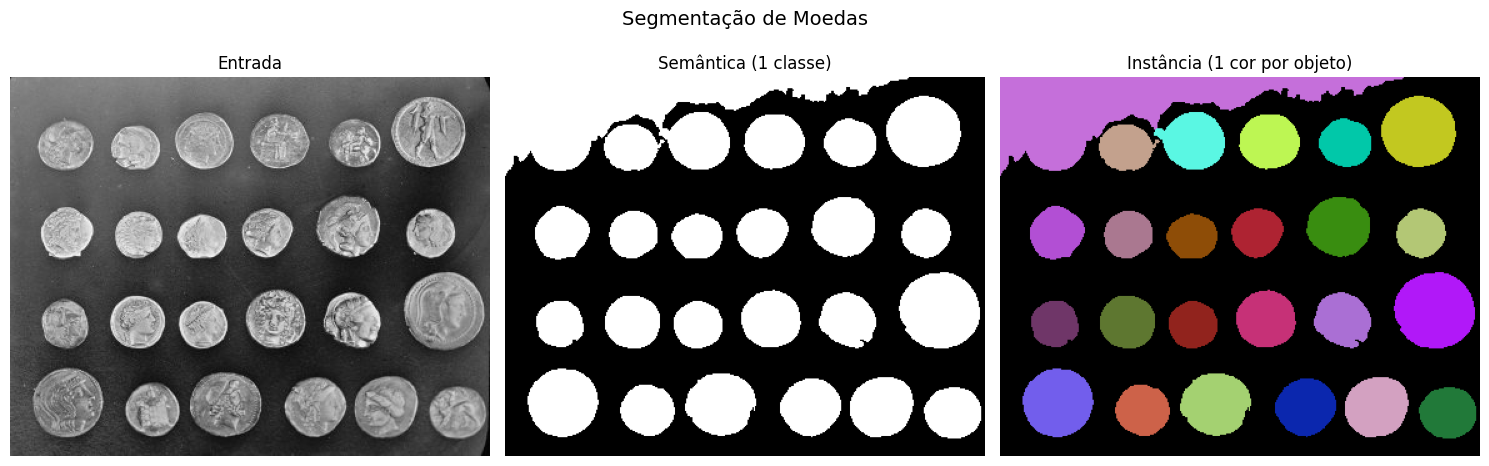

Quantidade de instâncias identificadas: 24


In [6]:
# Carregar imagem
moedas = data.coins()
suave = cv2.GaussianBlur(moedas, (5, 5), 0)
_, mascara_moedas = cv2.threshold(
    suave, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

mascara_moedas = mascara_moedas > 0

mascara_moedas = morphology.remove_small_objects(
    mascara_moedas, min_size=80
)

mascara_moedas = ndi.binary_fill_holes(mascara_moedas)

distancia = ndi.distance_transform_edt(mascara_moedas)

picos = peak_local_max(
    distancia,
    min_distance=24,
    threshold_abs=5,
    labels=mascara_moedas
)

marcadores = np.zeros(moedas.shape, dtype=np.int32)

for i, (y, x) in enumerate(picos, start=1):
    marcadores[y, x] = i

instancias_moedas = watershed(
    -distancia,
    marcadores,
    mask=mascara_moedas
)

comparar_segmentacoes(
    moedas,
    mascara_moedas,
    instancias_moedas,
    'Segmentação de Moedas'
)

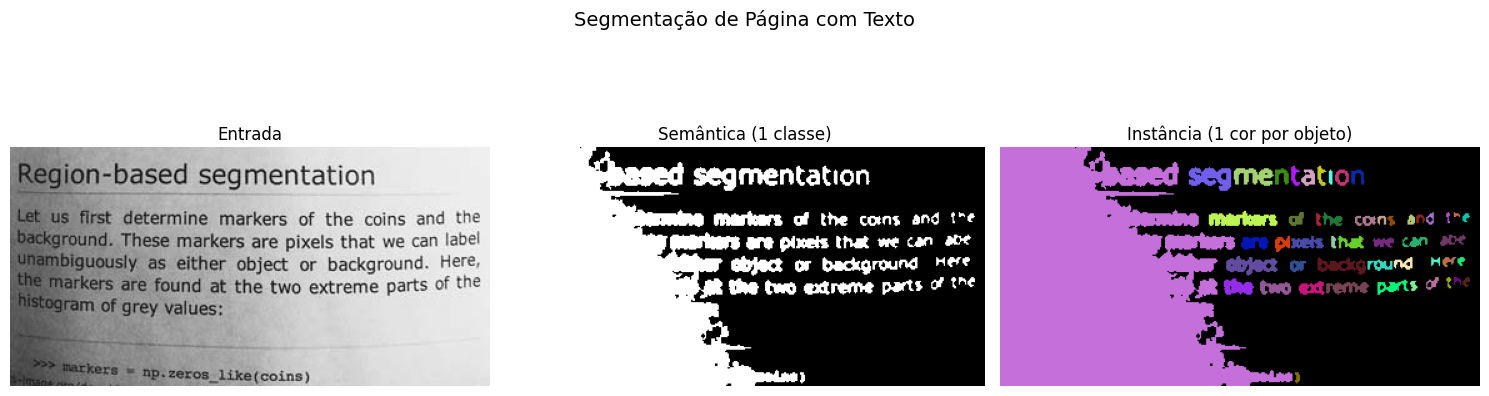

Quantidade de instâncias identificadas: 50


In [7]:
pagina = data.page()

suave_pagina = cv2.GaussianBlur(pagina, (5, 5), 0)

_, mascara_pagina = cv2.threshold(
    suave_pagina, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

mascara_pagina = mascara_pagina > 0

mascara_pagina = morphology.remove_small_objects(
    mascara_pagina, min_size=10
)

instancias_pagina = measure.label(
    mascara_pagina,
    connectivity=2
)

comparar_segmentacoes(
    pagina,
    mascara_pagina,
    instancias_pagina,
    'Segmentação de Página com Texto'
)

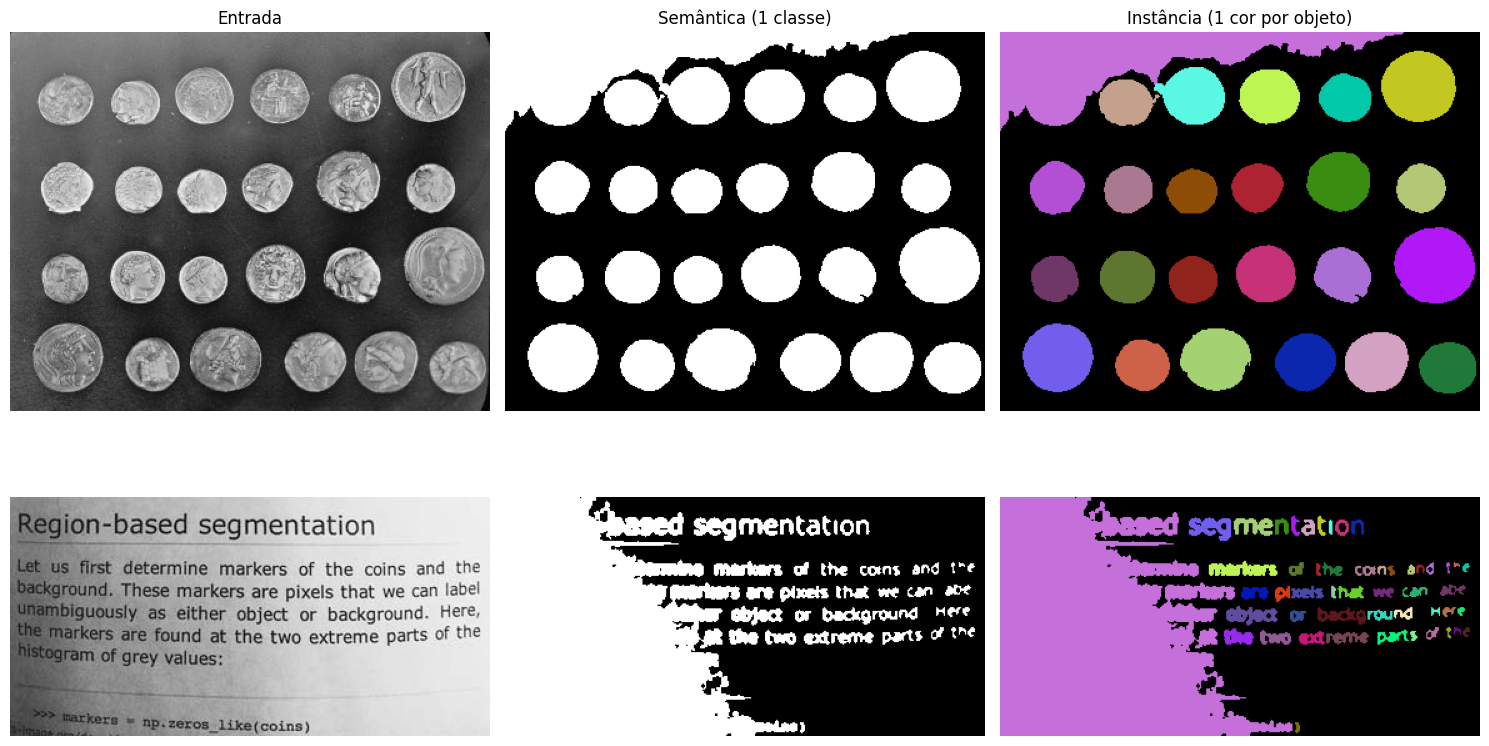

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(15, 9))

resultados = [
    (moedas, mascara_moedas, instancias_moedas, 'Moedas'),
    (pagina, mascara_pagina, instancias_pagina, 'Página')
]

for linha, (imagem, mascara, instancias, nome) in enumerate(resultados):

    n = int(instancias.max())
    rng = np.random.default_rng(42)

    cores = np.vstack([
        [0, 0, 0],
        rng.random((n, 3))
    ])

    ax[linha, 0].imshow(imagem, cmap='gray')
    ax[linha, 1].imshow(mascara, cmap='gray', vmin=0, vmax=1)

    ax[linha, 2].imshow(
        instancias,
        cmap=ListedColormap(cores),
        vmin=0,
        vmax=max(1, n)
    )

    ax[linha, 0].set_ylabel(nome, fontsize=13)

    for coluna in range(3):
        ax[linha, coluna].axis('off')

ax[0, 0].set_title('Entrada')
ax[0, 1].set_title('Semântica (1 classe)')
ax[0, 2].set_title('Instância (1 cor por objeto)')

plt.tight_layout()
plt.show()

### Análise dos resultados

Na imagem das moedas, a segmentação semântica identifica todas as moedas como uma única classe, enquanto a segmentação por instância tenta separar cada moeda utilizando cores diferentes.

Na imagem da página, a segmentação semântica identifica as regiões escuras do texto, enquanto a segmentação por instância separa os componentes conectados, que podem representar letras, partes de letras ou grupos de caracteres.

**Conclusão:** Houve diferença entre as duas imagens. As moedas apresentam objetos maiores e mais definidos, enquanto a página possui elementos menores e mais próximos, dificultando a separação individual. A segmentação por instância permite diferenciar objetos da mesma classe, mas sua precisão depende das características da imagem e do método utilizado.